<a href="https://colab.research.google.com/github/hafiashafqat/Scaled_Subtraction_Analysis/blob/main/Scaled_Subtraction_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Calculated Amplitude Scaling Factor (alpha): 0.9406


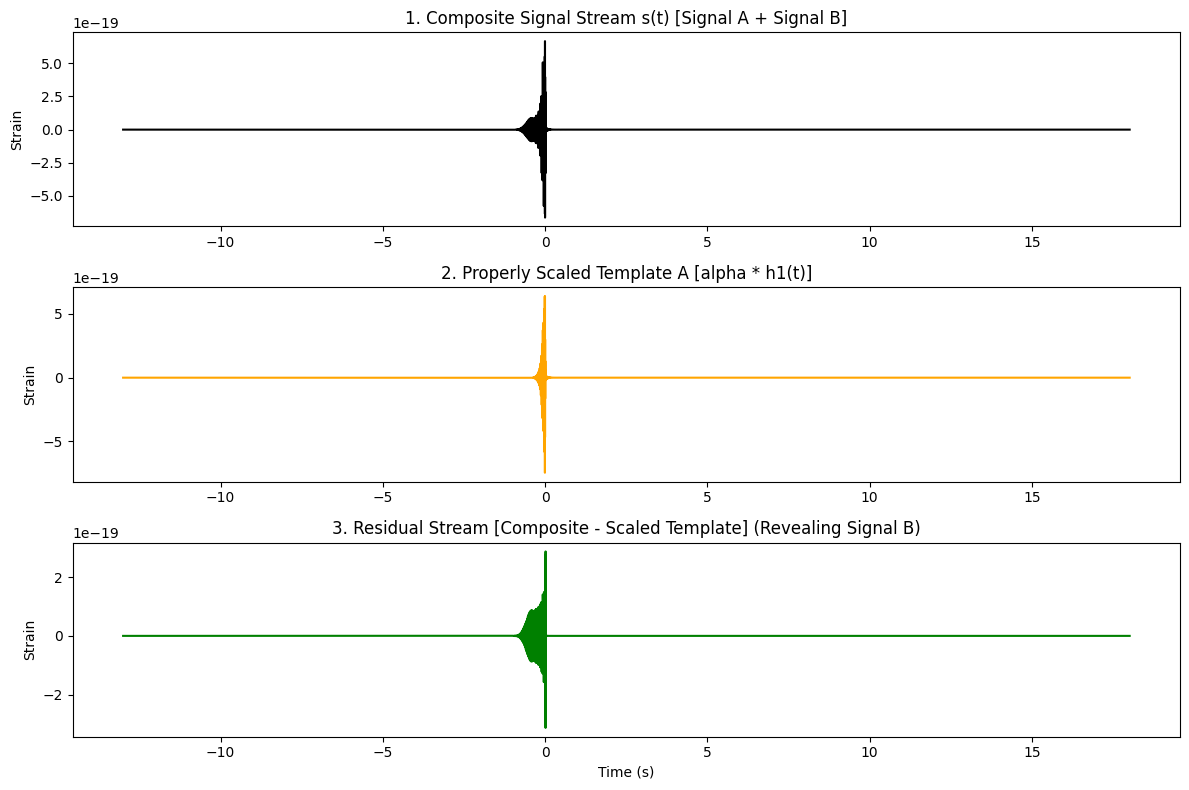

In [5]:
# 1. Install and import required libraries
!pip install -q pycbc
import numpy as np
import pylab as plt
from pycbc.waveform import get_td_waveform
from pycbc.types import TimeSeries

# 2. Generate waveforms using yesterday's exact parameters
hp1, hc1 = get_td_waveform(approximant="IMRPhenomD",
                           mass1=35,
                           mass2=30,
                           delta_t=1.0/4096,
                           f_lower=40)

hp2, hc2 = get_td_waveform(approximant="IMRPhenomD",
                           mass1=15,
                           mass2=12,
                           delta_t=1.0/4096,
                           f_lower=40)

# 3. Align and create composite stream safely on a common shared time grid
data1 = hp1.numpy()
data2 = hp2.numpy()
dt = hp1.delta_t

# Find the peak (merger) index of both waveforms
peak1 = abs(hp1).numpy().argmax()
peak2 = abs(hp2).numpy().argmax()

# 0.02 seconds time shift in samples
shift_samples = int(0.02 / dt)

# Define a safe target index dynamically to prevent negative slicing errors
target_idx = max(peak1, peak2) + int(2.0 / dt)
total_len = target_idx + max(len(data1), len(data2)) + abs(shift_samples) + int(2.0 / dt)

composite_data = np.zeros(total_len)
stream_data = np.zeros(total_len)

# Place Signal A safely at the target index
start1 = target_idx - peak1
end1 = start1 + len(data1)
stream_data[start1:end1] += data1
composite_data[start1:end1] += data1

# Place Signal B with the 0.02s time shift relative to Signal A's merger
start2 = target_idx - peak2 + shift_samples
end2 = start2 + len(data2)
composite_data[start2:end2] += data2

# Convert back to PyCBC TimeSeries with a synchronized epoch
epoch = hp1.start_time - start1 * dt
composite_stream = TimeSeries(composite_data, delta_t=dt, epoch=epoch)
stream = TimeSeries(stream_data, delta_t=dt, epoch=epoch)

# 4. Calculate the Amplitude Scaling Factor (Alpha) using Least Squares / Inner Product
numerator = np.dot(composite_stream.data, stream.data)
denominator = np.dot(stream.data, stream.data)
alpha = numerator / denominator

print(f"Calculated Amplitude Scaling Factor (alpha): {alpha:.4f}")

# 5. Build the scaled template and perform the subtraction
scaled_template = alpha * stream
residual_stream = composite_stream - scaled_template

# 6. Plot the results across multi-panel views
plt.figure(figsize=(12, 8))

plt.subplot(3, 1, 1)
plt.plot(composite_stream.sample_times, composite_stream, color='black')
plt.title("1. Composite Signal Stream s(t) [Signal A + Signal B]")
plt.ylabel("Strain")

plt.subplot(3, 1, 2)
plt.plot(scaled_template.sample_times, scaled_template, color='orange')
plt.title("2. Properly Scaled Template A [alpha * h1(t)]")
plt.ylabel("Strain")

plt.subplot(3, 1, 3)
plt.plot(residual_stream.sample_times, residual_stream, color='green')
plt.title("3. Residual Stream [Composite - Scaled Template] (Revealing Signal B)")
plt.xlabel("Time (s)")
plt.ylabel("Strain")

plt.tight_layout()
plt.show()